In [3]:
from IPython.display import HTML, display
import os

threejs_html = """
<!DOCTYPE html>
<html>
<head>
    <title>Gravitational Lensing 3D Schematic</title>
    <style>
        body { margin: 0; overflow: hidden; background-color: #0a1a2a; color: white; font-family: Arial, Helvetica, sans-serif; }
        #info {
            position: absolute;
            top: 20px;
            left: 20px;
            background: rgba(0,0,0,0.7);
            padding: 12px 20px;
            border-radius: 8px;
            pointer-events: none;
            z-index: 10;
            font-size: 14px;
        }
        #info h1 { margin: 0; font-size: 20px; color: #ffaa44; }
        #info p { margin: 5px 0 0 0; opacity: 0.8; }
    </style>
</head>
<body>
    <div id="info">
        <h1>🌌 Gravitational Lensing: Time Delay</h1>
        <p>Drag to rotate · Scroll to zoom</p>
    </div>

    <script type="importmap">
        {
            "imports": {
                "three": "https://unpkg.com/three@0.128.0/build/three.module.js",
                "three/addons/": "https://unpkg.com/three@0.128.0/examples/jsm/"
            }
        }
    </script>

    <script type="module">
        import * as THREE from 'three';
        import { OrbitControls } from 'three/addons/controls/OrbitControls.js';

        // --- 场景、相机、渲染器 ---
        const scene = new THREE.Scene();
        scene.background = new THREE.Color(0x0a1a2a); // 深蓝色背景

        const camera = new THREE.PerspectiveCamera(45, window.innerWidth / window.innerHeight, 0.1, 1000);
        camera.position.set(8, 5, 10);
        camera.lookAt(3, 0, 0);

        const renderer = new THREE.WebGLRenderer({ antialias: true });
        renderer.setSize(window.innerWidth, window.innerHeight);
        renderer.shadowMap.enabled = true;
        document.body.appendChild(renderer.domElement);

        // --- 控制器 ---
        const controls = new OrbitControls(camera, renderer.domElement);
        controls.target.set(3, 0, 0);
        controls.enableDamping = true;
        controls.dampingFactor = 0.05;
        controls.update();

        // --- 光源 (增强亮度) ---
        const ambientLight = new THREE.AmbientLight(0x404060, 0.8);
        scene.add(ambientLight);

        const dirLight = new THREE.DirectionalLight(0xffffff, 1.2);
        dirLight.position.set(2, 5, 3);
        scene.add(dirLight);

        const backLight = new THREE.DirectionalLight(0x4466ff, 0.6);
        backLight.position.set(-2, 1, -3);
        scene.add(backLight);

        const pointLight = new THREE.PointLight(0xffaa00, 0.8, 20);
        pointLight.position.set(2, 1, 2);
        scene.add(pointLight);

        // --- 星空粒子 (更亮一些) ---
        const starsGeometry = new THREE.BufferGeometry();
        const starsCount = 2000;
        const starPositions = new Float32Array(starsCount * 3);
        for (let i = 0; i < starsCount * 3; i += 3) {
            starPositions[i] = (Math.random() - 0.5) * 200;
            starPositions[i+1] = (Math.random() - 0.5) * 200;
            starPositions[i+2] = (Math.random() - 0.5) * 200;
        }
        starsGeometry.setAttribute('position', new THREE.BufferAttribute(starPositions, 3));
        const starsMaterial = new THREE.PointsMaterial({ color: 0x88aaff, size: 0.2, transparent: true });
        const stars = new THREE.Points(starsGeometry, starsMaterial);
        scene.add(stars);

        // --- 创建场景元素 (颜色加亮) ---

        // 地球 (亮绿色)
        const earthGeo = new THREE.SphereGeometry(0.6, 32, 32);
        const earthMat = new THREE.MeshStandardMaterial({ color: 0x33dd88, emissive: 0x116633, emissiveIntensity: 0.4 });
        const earth = new THREE.Mesh(earthGeo, earthMat);
        earth.position.set(0, 0, 0);
        scene.add(earth);

        // 透镜星系 (金色加亮)
        const lensGroup = new THREE.Group();
        lensGroup.position.set(2, 0, 0);
        const coreGeo = new THREE.SphereGeometry(0.4, 24, 24);
        const coreMat = new THREE.MeshStandardMaterial({ color: 0xffaa33, emissive: 0xcc7722, emissiveIntensity: 0.5 });
        const core = new THREE.Mesh(coreGeo, coreMat);
        lensGroup.add(core);
        const diskGeo = new THREE.TorusGeometry(0.9, 0.05, 16, 32);
        const diskMat = new THREE.MeshStandardMaterial({ color: 0xffaa33, emissive: 0x995522, emissiveIntensity: 0.4 });
        const disk = new THREE.Mesh(diskGeo, diskMat);
        disk.rotation.x = Math.PI / 2;
        lensGroup.add(disk);
        scene.add(lensGroup);

        // 引力环 (更亮)
        const ringPoints = [];
        for (let i = 0; i <= 64; i++) {
            const theta = (i / 64) * Math.PI * 2;
            ringPoints.push(new THREE.Vector3(2 + 1.2 * Math.cos(theta), 1.2 * Math.sin(theta), 0));
        }
        const ringGeo = new THREE.BufferGeometry().setFromPoints(ringPoints);
        const ringMat = new THREE.LineBasicMaterial({ color: 0xffaa44, transparent: true, opacity: 0.4 });
        const ringLine = new THREE.Line(ringGeo, ringMat);
        scene.add(ringLine);

        // FRB源 (亮黄色)
        const sourceGroup = new THREE.Group();
        sourceGroup.position.set(6, 0, 0);
        const sourceGeo = new THREE.SphereGeometry(0.5, 24, 24);
        const sourceMat = new THREE.MeshStandardMaterial({ color: 0xffdd44, emissive: 0xff8800, emissiveIntensity: 0.6 });
        const sourceMesh = new THREE.Mesh(sourceGeo, sourceMat);
        sourceGroup.add(sourceMesh);
        scene.add(sourceGroup);

        // --- 光路绘制 ---

        // 直接光路 (亮蓝色虚线)
        const directPoints = [];
        for (let i = 0; i <= 30; i++) {
            const t = i / 30;
            directPoints.push(new THREE.Vector3(6 * (1 - t), 0, 0));
        }
        const directGeo = new THREE.BufferGeometry().setFromPoints(directPoints);
        const directMat = new THREE.LineDashedMaterial({ color: 0x44aaff, dashSize: 0.15, gapSize: 0.1 });
        const directLine = new THREE.Line(directGeo, directMat);
        directLine.computeLineDistances();
        scene.add(directLine);

        // 弯曲光路 (亮红色实线)
        const curvedPoints = [];
        for (let i = 0; i <= 30; i++) {
            const t = i / 30;
            curvedPoints.push(new THREE.Vector3(6 * (1 - t), 1.8 * Math.sin(t * Math.PI), 0));
        }
        const curvedGeo = new THREE.BufferGeometry().setFromPoints(curvedPoints);
        const curvedMat = new THREE.LineBasicMaterial({ color: 0xff6666 });
        const curvedLine = new THREE.Line(curvedGeo, curvedMat);
        scene.add(curvedLine);

        // 光路方向小光球 (更亮)
        const spherePath = new THREE.Mesh(
            new THREE.SphereGeometry(0.15, 8, 8),
            new THREE.MeshBasicMaterial({ color: 0xff8888 })
        );
        scene.add(spherePath);
        const sphereDirect = new THREE.Mesh(
            new THREE.SphereGeometry(0.15, 8, 8),
            new THREE.MeshBasicMaterial({ color: 0x88ccff })
        );
        scene.add(sphereDirect);

        // --- 文字标签 (使用Canvas制作) ---
        function createLabel(text, position, color = '#ffffff', size = 0.6) {
            const canvas = document.createElement('canvas');
            const context = canvas.getContext('2d');
            canvas.width = 512;
            canvas.height = 128;
            context.clearRect(0, 0, canvas.width, canvas.height);
            context.font = 'Bold 36px Arial';
            context.textAlign = 'center';
            context.textBaseline = 'middle';
            context.fillStyle = color;
            context.shadowColor = 'black';
            context.shadowBlur = 10;
            context.fillText(text, canvas.width/2, canvas.height/2);
            const texture = new THREE.CanvasTexture(canvas);
            const material = new THREE.SpriteMaterial({ map: texture, transparent: true, depthTest: false });
            const sprite = new THREE.Sprite(material);
            sprite.position.set(position[0], position[1], position[2]);
            sprite.scale.set(size * 2, size * 0.5, 1);
            return sprite;
        }

        scene.add(createLabel('🌍 Earth', [0, -1.2, 0], '#88ffaa', 0.8));
        scene.add(createLabel('🌀 Lensing Galaxy', [2, -1.8, 0], '#ffaa33', 0.9));
        scene.add(createLabel('⭐ FRB Source', [6, -1.2, 0], '#ffdd44', 0.8));
        scene.add(createLabel('Direct Path', [3, -0.8, 0], '#44aaff', 0.7));
        scene.add(createLabel('Delayed Path', [3, 2.5, 0], '#ff6666', 0.7));
        scene.add(createLabel('⏱ Δt ≈ 24.9 days', [3, 3.6, 0], '#ffffff', 1.0));

        // --- 动画 ---
        let time = 0;
        function animate() {
            requestAnimationFrame(animate);
            time += 0.02;
            const pathPos = (Math.sin(time * 0.8) + 1) / 2;
            const idx = Math.floor(pathPos * 30);
            if (idx < curvedPoints.length) {
                spherePath.position.copy(curvedPoints[idx]);
                sphereDirect.position.copy(directPoints[idx]);
            }
            controls.update();
            renderer.render(scene, camera);
        }
        animate();

        // --- 窗口自适应 ---
        window.addEventListener('resize', () => {
            camera.aspect = window.innerWidth / window.innerHeight;
            camera.updateProjectionMatrix();
            renderer.setSize(window.innerWidth, window.innerHeight);
        });
    </script>
</body>
</html>
"""

# 显示在 Jupyter 中
display(HTML(threejs_html))

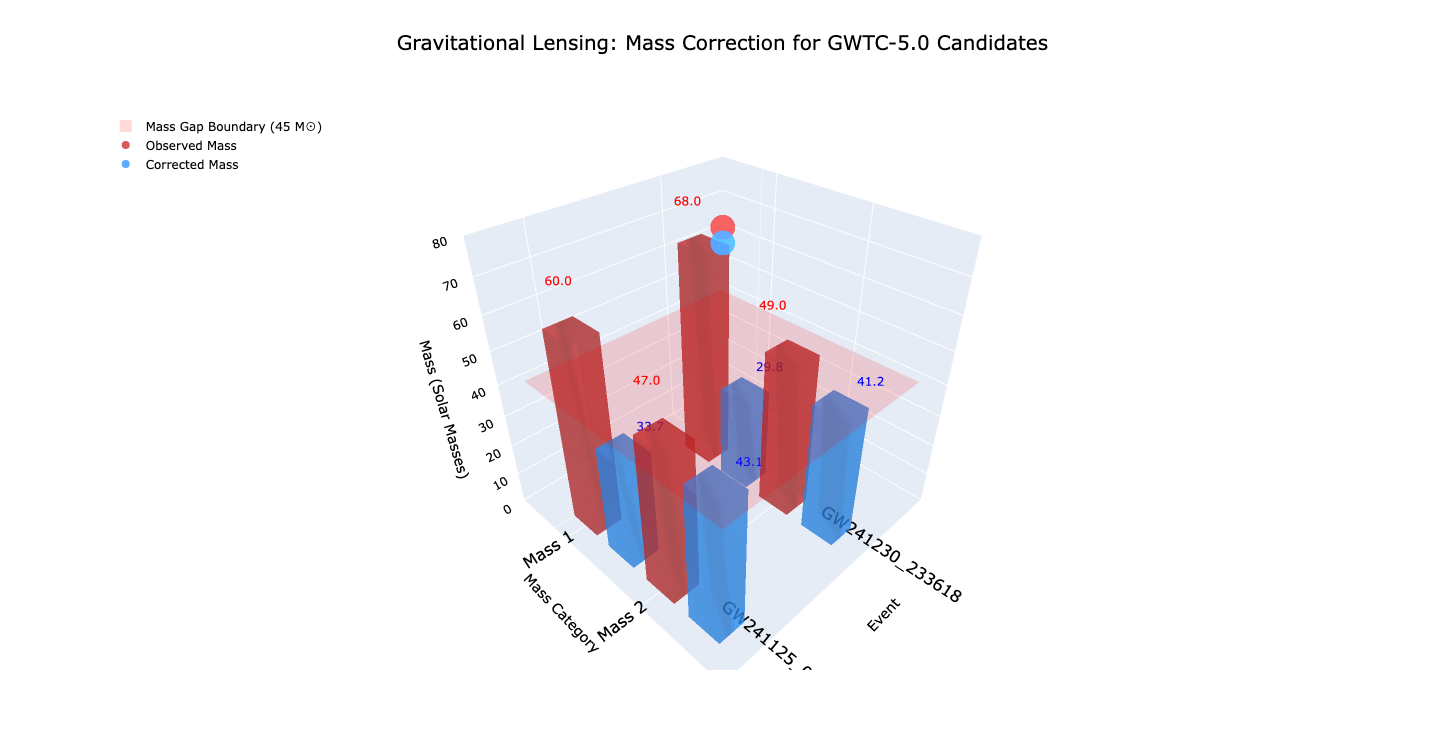

SUMMARY: Gravitational Lensing Mass Correction

GW241230_233618:
  Mass 1: Observed 68.0 M☉ → Corrected 29.8 M☉ (μ=2.28)
  Mass 2: Observed 49.0 M☉ → Corrected 41.2 M☉ (μ=1.19)

GW241125_010116:
  Mass 1: Observed 60.0 M☉ → Corrected 33.7 M☉ (μ=1.78)
  Mass 2: Observed 47.0 M☉ → Corrected 43.1 M☉ (μ=1.09)


In [6]:
import plotly.graph_objects as go
import numpy as np

# --- 1. 数据准备 ---
events = ['GW241230_233618', 'GW241125_010116']
mass_1_obs = [68.0, 60.0]
mass_2_obs = [49.0, 47.0]
lens_mag_1 = [2.28, 1.78]
lens_mag_2 = [1.19, 1.09]

mass_1_corr = [mass_1_obs[i] / lens_mag_1[i] for i in range(2)]
mass_2_corr = [mass_2_obs[i] / lens_mag_2[i] for i in range(2)]

mass_gap_boundary = 45.0

# --- 2. 辅助函数：创建单个条形的Mesh3d顶点 ---
def create_bar(x, y, z, dx, dy, dz, color, opacity=0.7):
    """创建一个3D条形 (使用8个顶点和12个三角形)"""
    # 8个顶点: (x, y, z) 到 (x+dx, y+dy, z+dz)
    vertices = np.array([
        [x, y, 0],
        [x+dx, y, 0],
        [x+dx, y+dy, 0],
        [x, y+dy, 0],
        [x, y, dz],
        [x+dx, y, dz],
        [x+dx, y+dy, dz],
        [x, y+dy, dz]
    ])
    
    # 12个三角形 (每个面2个三角形)
    triangles = np.array([
        # 底面
        [0, 1, 2], [0, 2, 3],
        # 顶面
        [4, 6, 5], [4, 7, 6],
        # 前面
        [0, 5, 1], [0, 4, 5],
        # 后面
        [3, 2, 6], [3, 6, 7],
        # 左面
        [0, 3, 7], [0, 7, 4],
        # 右面
        [1, 5, 6], [1, 6, 2]
    ])
    
    return go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=triangles[:, 0],
        j=triangles[:, 1],
        k=triangles[:, 2],
        color=color,
        opacity=opacity,
        hoverinfo='skip',
        showlegend=False
    )

# --- 3. 创建图形 ---
fig = go.Figure()

# 3.1 质量1: 观测值 (红色)
fig.add_trace(create_bar(0, 0, 0, 0.2, 0.4, mass_1_obs[0], 'rgba(200,50,50,0.8)'))
fig.add_trace(create_bar(1, 0, 0, 0.2, 0.4, mass_1_obs[1], 'rgba(200,50,50,0.8)'))

# 3.2 质量1: 修正值 (蓝色)
fig.add_trace(create_bar(0, 0.6, 0, 0.2, 0.4, mass_1_corr[0], 'rgba(50,150,255,0.8)'))
fig.add_trace(create_bar(1, 0.6, 0, 0.2, 0.4, mass_1_corr[1], 'rgba(50,150,255,0.8)'))

# 3.3 质量2: 观测值 (红色)
fig.add_trace(create_bar(0, 1.2, 0, 0.2, 0.4, mass_2_obs[0], 'rgba(200,50,50,0.8)'))
fig.add_trace(create_bar(1, 1.2, 0, 0.2, 0.4, mass_2_obs[1], 'rgba(200,50,50,0.8)'))

# 3.4 质量2: 修正值 (蓝色)
fig.add_trace(create_bar(0, 1.8, 0, 0.2, 0.4, mass_2_corr[0], 'rgba(50,150,255,0.8)'))
fig.add_trace(create_bar(1, 1.8, 0, 0.2, 0.4, mass_2_corr[1], 'rgba(50,150,255,0.8)'))

# --- 4. 添加质量间隙边界平面 (半透明红色) ---
x_plane = np.array([-0.3, 1.3, 1.3, -0.3])
y_plane = np.array([-0.2, -0.2, 2.4, 2.4])
z_plane = np.full_like(x_plane, mass_gap_boundary)

fig.add_trace(go.Mesh3d(
    x=x_plane,
    y=y_plane,
    z=z_plane,
    color='red',
    opacity=0.15,
    name='Mass Gap Boundary (45 M☉)',
    showlegend=True,
    hoverinfo='skip'
))

# --- 5. 添加数值标签 (使用 Scatter3d) ---
# 质量1观测值标签
fig.add_trace(go.Scatter3d(
    x=[0, 1], y=[-0.2, -0.2], z=[mass_1_obs[0]+3, mass_1_obs[1]+3],
    mode='text',
    text=[f'{mass_1_obs[0]:.1f}', f'{mass_1_obs[1]:.1f}'],
    textfont=dict(color='red', size=12),
    showlegend=False,
    hoverinfo='skip'
))

# 质量1修正值标签
fig.add_trace(go.Scatter3d(
    x=[0, 1], y=[1.0, 1.0], z=[mass_1_corr[0]+3, mass_1_corr[1]+3],
    mode='text',
    text=[f'{mass_1_corr[0]:.1f}', f'{mass_1_corr[1]:.1f}'],
    textfont=dict(color='blue', size=12),
    showlegend=False,
    hoverinfo='skip'
))

# 质量2观测值标签
fig.add_trace(go.Scatter3d(
    x=[0, 1], y=[1.0, 1.0], z=[mass_2_obs[0]+3, mass_2_obs[1]+3],
    mode='text',
    text=[f'{mass_2_obs[0]:.1f}', f'{mass_2_obs[1]:.1f}'],
    textfont=dict(color='red', size=12),
    showlegend=False,
    hoverinfo='skip'
))

# 质量2修正值标签
fig.add_trace(go.Scatter3d(
    x=[0, 1], y=[2.2, 2.2], z=[mass_2_corr[0]+3, mass_2_corr[1]+3],
    mode='text',
    text=[f'{mass_2_corr[0]:.1f}', f'{mass_2_corr[1]:.1f}'],
    textfont=dict(color='blue', size=12),
    showlegend=False,
    hoverinfo='skip'
))

# --- 6. 添加图例 (使用 Scatter3d 模拟) ---
fig.add_trace(go.Scatter3d(
    x=[-0.5], y=[-0.5], z=[60],
    mode='markers',
    marker=dict(size=8, color='rgba(200,50,50,0.8)'),
    name='Observed Mass'
))
fig.add_trace(go.Scatter3d(
    x=[-0.5], y=[-0.5], z=[55],
    mode='markers',
    marker=dict(size=8, color='rgba(50,150,255,0.8)'),
    name='Corrected Mass'
))

# --- 7. 设置布局 ---
fig.update_layout(
    title=dict(
        text='Gravitational Lensing: Mass Correction for GWTC-5.0 Candidates',
        font=dict(size=20),
        x=0.5
    ),
    scene=dict(
        xaxis=dict(
            title='Event',
            tickvals=[0, 1],
            ticktext=events,
            tickfont=dict(size=14)
        ),
        yaxis=dict(
            title='Mass Category',
            tickvals=[0.2, 1.4],
            ticktext=['Mass 1', 'Mass 2'],
            tickfont=dict(size=14)
        ),
        zaxis=dict(
            title='Mass (Solar Masses)',
            range=[0, 80],
            tickfont=dict(size=12)
        ),
        bgcolor='white'
    ),
    width=1000,
    height=750,
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255,255,255,0.9)',
        font=dict(size=12)
    ),
    font=dict(color='black')
)

fig.show()

# --- 8. 打印数值摘要 ---
print("="*60)
print("SUMMARY: Gravitational Lensing Mass Correction")
print("="*60)
for i, event in enumerate(events):
    print(f"\n{event}:")
    print(f"  Mass 1: Observed {mass_1_obs[i]:.1f} M☉ → Corrected {mass_1_corr[i]:.1f} M☉ (μ={lens_mag_1[i]:.2f})")
    print(f"  Mass 2: Observed {mass_2_obs[i]:.1f} M☉ → Corrected {mass_2_corr[i]:.1f} M☉ (μ={lens_mag_2[i]:.2f})")
print("="*60)

✅ GIF已保存为: mass_correction_animation.gif


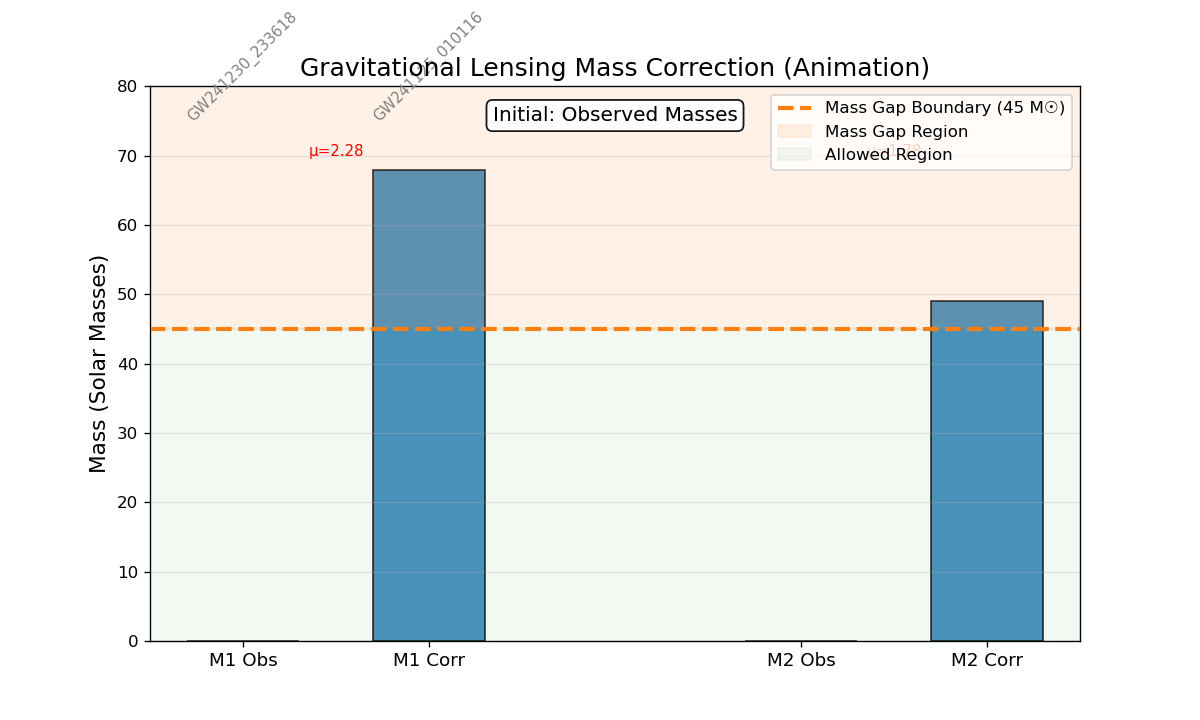

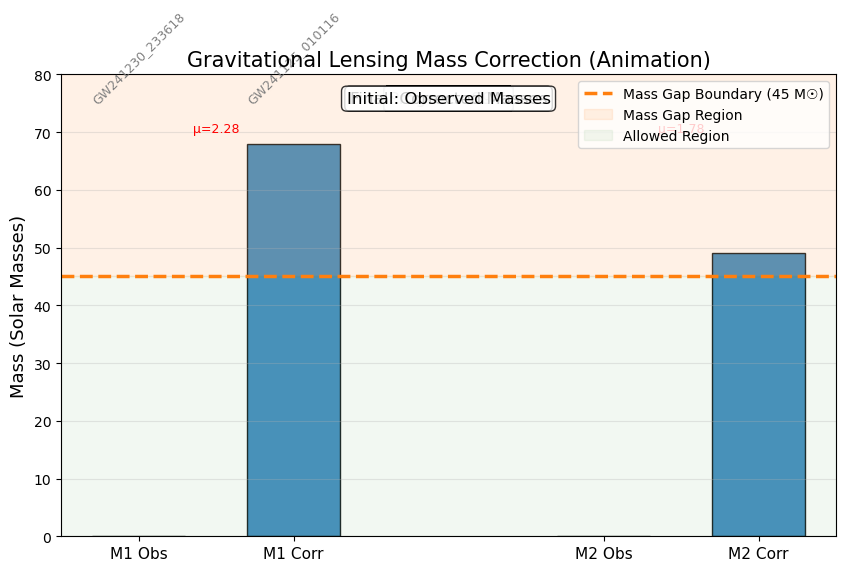

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import matplotlib.patches as patches

# --- 1. 数据准备 ---
events = ['GW241230_233618', 'GW241125_010116']
m1_obs = [68.0, 60.0]
m1_corr = [29.8, 33.7]
m2_obs = [49.0, 47.0]
m2_corr = [41.2, 43.1]
gap_boundary = 45.0

# --- 2. 创建动画 ---
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('white')

# 颜色定义
obs_color = '#d62728'      # 红色
corr_color = '#1f77b4'     # 蓝色
gap_color = '#ff7f0e'      # 橙色

# 条形位置
x_pos = np.array([0, 1, 3, 4])  # M1_obs, M1_corr, M2_obs, M2_corr
width = 0.6
gap_line_x = [-0.5, 4.5]

# 初始化条形
bars = ax.bar(x_pos, [0, 0, 0, 0], width, 
              color=[obs_color, corr_color, obs_color, corr_color],
              alpha=0.8, edgecolor='black', linewidth=1)

# 设置坐标轴
ax.set_ylim(0, 80)
ax.set_xlim(-0.5, 4.5)
ax.set_xticks([0, 1, 3, 4])
ax.set_xticklabels(['M1 Obs', 'M1 Corr', 'M2 Obs', 'M2 Corr'], fontsize=11)
ax.set_ylabel('Mass (Solar Masses)', fontsize=13)
ax.set_title('Gravitational Lensing Mass Correction (Animation)', fontsize=15)

# 添加质量间隙边界线 (虚线)
gap_line = ax.axhline(y=gap_boundary, color=gap_color, linestyle='--', linewidth=2.5, 
                      label=f'Mass Gap Boundary (45 M☉)')
# 添加填充区域 (质量间隙区域)
ax.axhspan(gap_boundary, 80, alpha=0.1, color=gap_color, label='Mass Gap Region')
ax.axhspan(0, gap_boundary, alpha=0.05, color='green', label='Allowed Region')

# 添加图例
ax.legend(loc='upper right', fontsize=10)

# 添加网格
ax.grid(axis='y', alpha=0.3)

# 显示事件名称 (在顶部)
for i, event in enumerate(events):
    ax.text(i, 75, event, ha='center', fontsize=9, rotation=45, color='gray')

# 添加注解：透镜放大倍数
ax.text(0.5, 70, 'μ=2.28', ha='center', fontsize=9, color='red')
ax.text(3.5, 70, 'μ=1.78', ha='center', fontsize=9, color='red')

# --- 3. 动画更新函数 ---
def update(frame):
    # frame: 0-100 映射到修正进度 0 -> 1
    progress = frame / 100.0
    
    # 目标高度 (最终高度)
    target_heights = [m1_obs[0], m1_corr[0], m2_obs[0], m2_corr[0]]
    
    # 计算当前高度: 从观测值开始，逐渐向修正值移动
    # 对于观测值 (索引0和2)，保持不变 (从0开始增长到观测值)
    # 对于修正值 (索引1和3)，从观测值逐渐下降到修正值
    
    # 两个事件
    # 事件1: GW241230_233618
    h_obs1 = m1_obs[0] * progress  # 从0增长到观测值
    h_corr1 = m1_obs[0] - (m1_obs[0] - m1_corr[0]) * progress  # 从观测值下降到修正值
    
    # 事件2: GW241125_010116
    h_obs2 = m2_obs[0] * progress
    h_corr2 = m2_obs[0] - (m2_obs[0] - m2_corr[0]) * progress
    
    # 更新条形高度
    bars[0].set_height(h_obs1)
    bars[1].set_height(h_corr1)
    bars[2].set_height(h_obs2)
    bars[3].set_height(h_corr2)
    
    # 更新条形位置 (保持底部在y=0)
    bars[0].set_y(0)
    bars[1].set_y(0)
    bars[2].set_y(0)
    bars[3].set_y(0)
    
    # 添加进度文字
    if frame == 0:
        ax.text(2, 75, 'Initial: Observed Masses', ha='center', fontsize=12, 
                color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    elif frame == 100:
        ax.text(2, 75, 'Final: Corrected Masses', ha='center', fontsize=12,
                color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    else:
        # 更新文字 (清除旧文字，添加新文字)
        for text in ax.texts:
            if 'Initial' in text.get_text() or 'Final' in text.get_text() or 'progress' in text.get_text():
                text.remove()
        ax.text(2, 75, f'Progress: {progress*100:.0f}%', ha='center', fontsize=12,
                color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    return bars

# --- 4. 生成动画 ---
ani = FuncAnimation(fig, update, frames=101, interval=50, blit=False, repeat=True)

# --- 5. 保存为GIF (需要安装pillow) ---
try:
    # 保存为GIF，显示所有帧
    ani.save('mass_correction_animation.gif', writer=PillowWriter(fps=20), dpi=120)
    print("✅ GIF已保存为: mass_correction_animation.gif")
except Exception as e:
    print(f"⚠️ 保存GIF时出错: {e}")
    print("   (可能没有安装pillow，尝试运行: !pip install pillow)")

# 在Jupyter中显示动画
from IPython.display import Image
try:
    display(Image(filename='mass_correction_animation.gif'))
except:
    print("在Jupyter中显示GIF失败，但文件已保存。你可以直接打开 'mass_correction_animation.gif' 查看。")

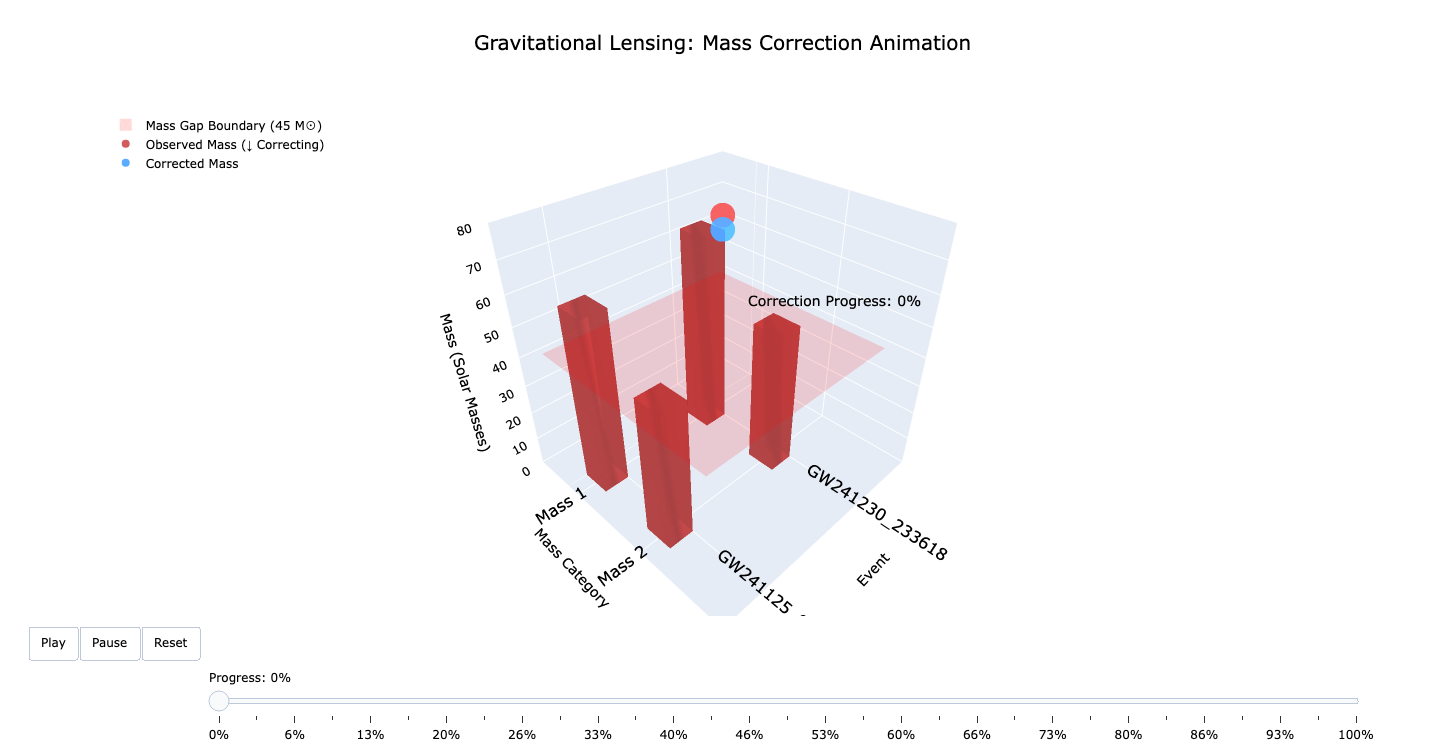

SUMMARY: Gravitational Lensing Mass Correction

GW241230_233618:
  Mass 1: Observed 68.0 M☉ → Corrected 29.8 M☉ (μ=2.28)
  Mass 2: Observed 49.0 M☉ → Corrected 41.2 M☉ (μ=1.19)

GW241125_010116:
  Mass 1: Observed 60.0 M☉ → Corrected 33.7 M☉ (μ=1.78)
  Mass 2: Observed 47.0 M☉ → Corrected 43.1 M☉ (μ=1.09)


In [9]:
import plotly.graph_objects as go
import numpy as np

# --- 1. 数据准备 ---
events = ['GW241230_233618', 'GW241125_010116']
mass_1_obs = [68.0, 60.0]
mass_2_obs = [49.0, 47.0]
lens_mag_1 = [2.28, 1.78]
lens_mag_2 = [1.19, 1.09]

mass_1_corr = [mass_1_obs[i] / lens_mag_1[i] for i in range(2)]
mass_2_corr = [mass_2_obs[i] / lens_mag_2[i] for i in range(2)]

mass_gap_boundary = 45.0

# --- 2. 辅助函数：创建单个条形的Mesh3d顶点 ---
def create_bar_vertices(x, y, z, dx, dy, dz):
    """返回一个条形的顶点和三角形索引"""
    vertices = np.array([
        [x, y, 0],
        [x+dx, y, 0],
        [x+dx, y+dy, 0],
        [x, y+dy, 0],
        [x, y, dz],
        [x+dx, y, dz],
        [x+dx, y+dy, dz],
        [x, y+dy, dz]
    ])
    triangles = np.array([
        [0, 1, 2], [0, 2, 3],
        [4, 6, 5], [4, 7, 6],
        [0, 5, 1], [0, 4, 5],
        [3, 2, 6], [3, 6, 7],
        [0, 3, 7], [0, 7, 4],
        [1, 5, 6], [1, 6, 2]
    ])
    return vertices, triangles

# --- 3. 定义所有条形的参数 ---
# 每个条形: [x, y, dx, dy, 观测高度, 修正高度, 颜色(观测), 颜色(修正)]
bars_config = [
    # 事件1: Mass 1
    {'x': 0, 'y': 0, 'dx': 0.2, 'dy': 0.4, 'h_obs': mass_1_obs[0], 'h_corr': mass_1_corr[0], 
     'color_obs': 'rgba(200,50,50,0.8)', 'color_corr': 'rgba(50,150,255,0.8)'},
    # 事件1: Mass 2
    {'x': 0, 'y': 1.2, 'dx': 0.2, 'dy': 0.4, 'h_obs': mass_2_obs[0], 'h_corr': mass_2_corr[0],
     'color_obs': 'rgba(200,50,50,0.8)', 'color_corr': 'rgba(50,150,255,0.8)'},
    # 事件2: Mass 1
    {'x': 1, 'y': 0, 'dx': 0.2, 'dy': 0.4, 'h_obs': mass_1_obs[1], 'h_corr': mass_1_corr[1],
     'color_obs': 'rgba(200,50,50,0.8)', 'color_corr': 'rgba(50,150,255,0.8)'},
    # 事件2: Mass 2
    {'x': 1, 'y': 1.2, 'dx': 0.2, 'dy': 0.4, 'h_obs': mass_2_obs[1], 'h_corr': mass_2_corr[1],
     'color_obs': 'rgba(200,50,50,0.8)', 'color_corr': 'rgba(50,150,255,0.8)'}
]

# --- 4. 创建帧 ---
frames = []
n_frames = 30  # 动画帧数

for frame_idx in range(n_frames + 1):
    progress = frame_idx / n_frames  # 0 -> 1
    data = []
    
    # 为每个条形生成当前帧的Mesh3d
    for bar in bars_config:
        # 当前高度: 从观测值线性过渡到修正值
        h_current = bar['h_obs'] - (bar['h_obs'] - bar['h_corr']) * progress
        # 当前颜色: 从红色渐变到蓝色
        r = 200 - (200 - 50) * progress
        g = 50 + (150 - 50) * progress
        b = 50 + (255 - 50) * progress
        color = f'rgba({int(r)},{int(g)},{int(b)},0.8)'
        
        vertices, triangles = create_bar_vertices(
            bar['x'], bar['y'], 0, bar['dx'], bar['dy'], h_current
        )
        
        data.append(go.Mesh3d(
            x=vertices[:, 0],
            y=vertices[:, 1],
            z=vertices[:, 2],
            i=triangles[:, 0],
            j=triangles[:, 1],
            k=triangles[:, 2],
            color=color,
            opacity=0.8,
            hoverinfo='skip',
            showlegend=False
        ))
    
    # 添加进度标签 (在场景中显示)
    data.append(go.Scatter3d(
        x=[0.5], y=[2.6], z=[70],
        mode='text',
        text=[f'Correction Progress: {int(progress*100)}%'],
        textfont=dict(color='black', size=14),
        showlegend=False,
        hoverinfo='skip'
    ))
    
    frames.append(go.Frame(data=data, name=f'frame{frame_idx}'))

# --- 5. 创建初始图形 (第一帧) ---
# 初始状态: progress = 0 (只有观测值)
initial_data = []
for bar in bars_config:
    vertices, triangles = create_bar_vertices(
        bar['x'], bar['y'], 0, bar['dx'], bar['dy'], bar['h_obs']
    )
    initial_data.append(go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=triangles[:, 0],
        j=triangles[:, 1],
        k=triangles[:, 2],
        color=bar['color_obs'],
        opacity=0.8,
        hoverinfo='skip',
        showlegend=False
    ))

# 添加质量间隙边界平面
x_plane = np.array([-0.3, 1.3, 1.3, -0.3])
y_plane = np.array([-0.2, -0.2, 2.4, 2.4])
z_plane = np.full_like(x_plane, mass_gap_boundary)
initial_data.append(go.Mesh3d(
    x=x_plane,
    y=y_plane,
    z=z_plane,
    color='red',
    opacity=0.15,
    name='Mass Gap Boundary (45 M☉)',
    showlegend=True,
    hoverinfo='skip'
))

# 添加初始进度标签
initial_data.append(go.Scatter3d(
    x=[0.5], y=[2.6], z=[70],
    mode='text',
    text=['Correction Progress: 0%'],
    textfont=dict(color='black', size=14),
    showlegend=False,
    hoverinfo='skip'
))

# 添加图例
initial_data.append(go.Scatter3d(
    x=[-0.5], y=[-0.5], z=[60],
    mode='markers',
    marker=dict(size=8, color='rgba(200,50,50,0.8)'),
    name='Observed Mass (↓ Correcting)'
))
initial_data.append(go.Scatter3d(
    x=[-0.5], y=[-0.5], z=[55],
    mode='markers',
    marker=dict(size=8, color='rgba(50,150,255,0.8)'),
    name='Corrected Mass'
))

# --- 6. 创建图形 ---
fig = go.Figure(
    data=initial_data,
    layout=go.Layout(
        title=dict(
            text='Gravitational Lensing: Mass Correction Animation',
            font=dict(size=20),
            x=0.5
        ),
        scene=dict(
            xaxis=dict(
                title='Event',
                tickvals=[0, 1],
                ticktext=events,
                tickfont=dict(size=14)
            ),
            yaxis=dict(
                title='Mass Category',
                tickvals=[0.2, 1.4],
                ticktext=['Mass 1', 'Mass 2'],
                tickfont=dict(size=14)
            ),
            zaxis=dict(
                title='Mass (Solar Masses)',
                range=[0, 80],
                tickfont=dict(size=12)
            ),
            bgcolor='white'
        ),
        width=1000,
        height=750,
        legend=dict(
            x=0.02,
            y=0.98,
            bgcolor='rgba(255,255,255,0.9)',
            font=dict(size=12)
        ),
        font=dict(color='black'),
        # 动画控制: 添加滑块和播放按钮
        updatemenus=[dict(
            type='buttons',
            buttons=[
                dict(label='Play',
                     method='animate',
                     args=[None, {'frame': {'duration': 100, 'redraw': True},
                                  'fromcurrent': True, 'transition': {'duration': 50}}]),
                dict(label='Pause',
                     method='animate',
                     args=[[None], {'frame': {'duration': 0, 'redraw': False},
                                    'mode': 'immediate',
                                    'transition': {'duration': 0}}]),
                dict(label='Reset',
                     method='animate',
                     args=[[None], {'frame': {'duration': 0, 'redraw': True},
                                    'mode': 'immediate',
                                    'transition': {'duration': 0}}])
            ],
            direction='left',
            pad={'r': 10, 't': 10},
            showactive=False,
            x=0.1,
            y=0,
            xanchor='right',
            yanchor='top'
        )],
        sliders=[dict(
            steps=[
                dict(
                    args=[
                        [f'frame{k}'],
                        {'frame': {'duration': 50, 'redraw': True},
                         'mode': 'immediate',
                         'transition': {'duration': 30}}
                    ],
                    label=f'{int(k/n_frames*100)}%',
                    method='animate'
                ) for k in range(n_frames + 1)
            ],
            active=0,
            currentvalue={'prefix': 'Progress: '},
            pad={'t': 50},
            len=0.9,
            x=0.1,
            y=0,
            xanchor='left',
            yanchor='top'
        )],
        # 添加默认的自动播放
        # 第一次显示时自动播放
    ),
    frames=frames
)

# 添加自动播放的动画（延迟一点开始）
# 使用 plotly 的 frame 自动播放
fig.show()

# --- 打印数值摘要 ---
print("="*60)
print("SUMMARY: Gravitational Lensing Mass Correction")
print("="*60)
for i, event in enumerate(events):
    print(f"\n{event}:")
    print(f"  Mass 1: Observed {mass_1_obs[i]:.1f} M☉ → Corrected {mass_1_corr[i]:.1f} M☉ (μ={lens_mag_1[i]:.2f})")
    print(f"  Mass 2: Observed {mass_2_obs[i]:.1f} M☉ → Corrected {mass_2_corr[i]:.1f} M☉ (μ={lens_mag_2[i]:.2f})")
print("="*60)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 读取数据
df_gw = pd.read_csv('GWTC-5.0.csv')

# 打印所有列名
print("列名列表：")
print(df_gw.columns.tolist())

# 打印候选体的数据
candidate_names = ['GW241230_233618', 'GW241125_010116']
candidates = df_gw[df_gw['name'].isin(candidate_names)]
print("\n候选体数据：")
print(candidates[['name', 'mass_1_source', 'mass_2_source']].head())

列名列表：
['name', 'shortName', 'gps', 'version', 'catalog', 'doi', 'detail_url', 'mass_1_source', 'mass_1_source_lower', 'mass_1_source_upper', 'mass_2_source', 'mass_2_source_lower', 'mass_2_source_upper', 'network_matched_filter_snr', 'network_matched_filter_snr_lower', 'network_matched_filter_snr_upper', 'luminosity_distance', 'luminosity_distance_lower', 'luminosity_distance_upper', 'chi_eff', 'chi_eff_lower', 'chi_eff_upper', 'total_mass_source', 'total_mass_source_lower', 'total_mass_source_upper', 'chirp_mass_source', 'chirp_mass_source_lower', 'chirp_mass_source_upper', 'chirp_mass', 'chirp_mass_lower', 'chirp_mass_upper', 'redshift', 'redshift_lower', 'redshift_upper', 'far', 'far_lower', 'far_upper', 'p_astro', 'p_astro_lower', 'p_astro_upper', 'final_mass_source', 'final_mass_source_lower', 'final_mass_source_upper']

候选体数据：
               name  mass_1_source  mass_2_source
17  GW241230_233618           68.0           49.0
34  GW241125_010116           60.0           47.0


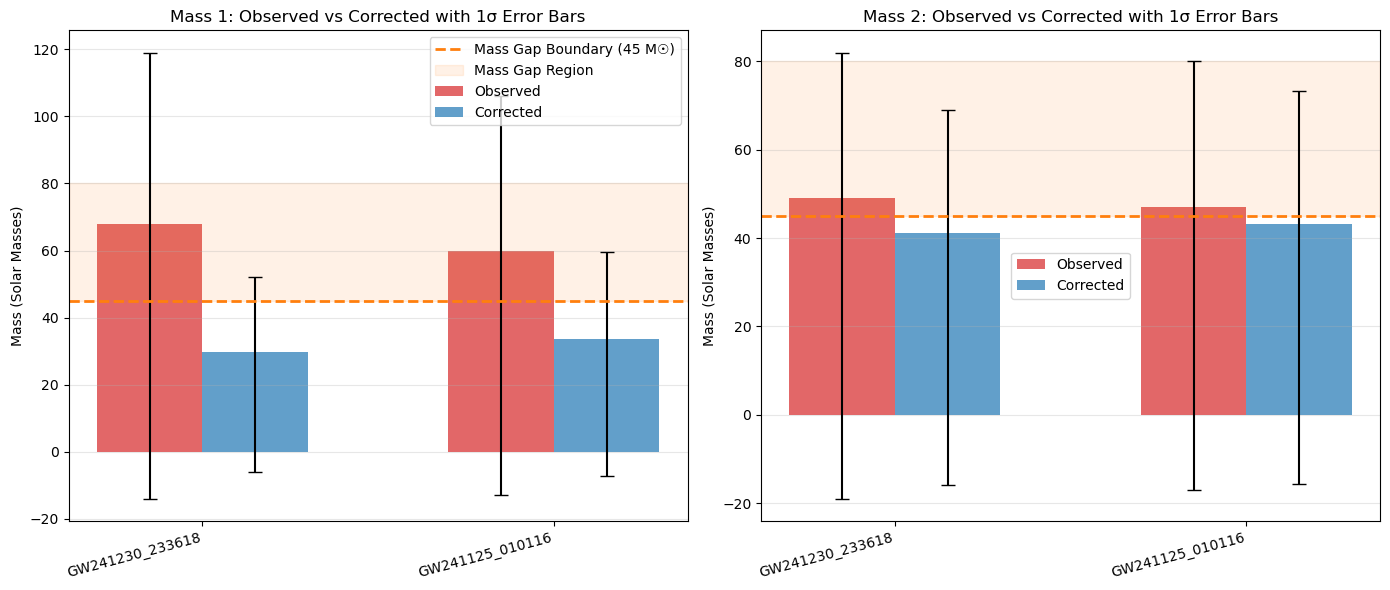

MASS CORRECTION WITH 1σ UNCERTAINTIES

GW241230_233618:
  Mass 1: 68.0 ± 51.0 M☉
       → Corrected: 29.8 M☉ (μ=2.28)
  Mass 2: 49.0 ± 33.0 M☉
       → Corrected: 41.2 M☉ (μ=1.19)

GW241125_010116:
  Mass 1: 60.0 ± 46.0 M☉
       → Corrected: 33.7 M☉ (μ=1.78)
  Mass 2: 47.0 ± 33.0 M☉
       → Corrected: 43.1 M☉ (μ=1.09)


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. 读取数据 ---
df_gw = pd.read_csv('GWTC-5.0.csv')

# --- 2. 筛选两个候选体 ---
candidate_names = ['GW241230_233618', 'GW241125_010116']
candidates = df_gw[df_gw['name'].isin(candidate_names)].copy()

# --- 3. 定义透镜放大倍数 ---
lens_mag_1 = [2.28, 1.78]
lens_mag_2 = [1.19, 1.09]

# --- 4. 计算修正值 ---
candidates['mass_1_corr'] = candidates['mass_1_source'] / lens_mag_1
candidates['mass_2_corr'] = candidates['mass_2_source'] / lens_mag_2

# --- 5. 计算修正值的误差（使用绝对值） ---
candidates['mass_1_corr_lower'] = candidates['mass_1_source_lower'] / lens_mag_1
candidates['mass_1_corr_upper'] = candidates['mass_1_source_upper'] / lens_mag_1
candidates['mass_2_corr_lower'] = candidates['mass_2_source_lower'] / lens_mag_2
candidates['mass_2_corr_upper'] = candidates['mass_2_source_upper'] / lens_mag_2

# --- 6. 计算 yerr（确保非负） ---
# 使用绝对值来处理 lower > best 的情况
yerr_1_obs = [abs(candidates['mass_1_source'] - candidates['mass_1_source_lower']),
              abs(candidates['mass_1_source_upper'] - candidates['mass_1_source'])]
yerr_1_corr = [abs(candidates['mass_1_corr'] - candidates['mass_1_corr_lower']),
               abs(candidates['mass_1_corr_upper'] - candidates['mass_1_corr'])]
yerr_2_obs = [abs(candidates['mass_2_source'] - candidates['mass_2_source_lower']),
              abs(candidates['mass_2_source_upper'] - candidates['mass_2_source'])]
yerr_2_corr = [abs(candidates['mass_2_corr'] - candidates['mass_2_corr_lower']),
               abs(candidates['mass_2_corr_upper'] - candidates['mass_2_corr'])]

# --- 7. 绘制带误差棒的条形图 ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

obs_color = '#d62728'
corr_color = '#1f77b4'
gap_color = '#ff7f0e'

# 7.1 Mass 1
ax = axes[0]
x_pos = np.arange(len(candidates))
width = 0.3

# 观测值（红色）
ax.bar(x_pos - width/2, candidates['mass_1_source'], width,
       yerr=[yerr_1_obs[0].values, yerr_1_obs[1].values],
       color=obs_color, alpha=0.7, label='Observed', capsize=5, error_kw={'linewidth': 1.5})

# 修正值（蓝色）
ax.bar(x_pos + width/2, candidates['mass_1_corr'], width,
       yerr=[yerr_1_corr[0].values, yerr_1_corr[1].values],
       color=corr_color, alpha=0.7, label='Corrected', capsize=5, error_kw={'linewidth': 1.5})

ax.axhline(45, color=gap_color, linestyle='--', linewidth=2, label='Mass Gap Boundary (45 M☉)')
ax.axhspan(45, 80, alpha=0.1, color=gap_color, label='Mass Gap Region')

ax.set_xticks(x_pos)
ax.set_xticklabels(candidates['name'], rotation=15, ha='right')
ax.set_ylabel('Mass (Solar Masses)')
ax.set_title('Mass 1: Observed vs Corrected with 1σ Error Bars')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 7.2 Mass 2
ax = axes[1]
ax.bar(x_pos - width/2, candidates['mass_2_source'], width,
       yerr=[yerr_2_obs[0].values, yerr_2_obs[1].values],
       color=obs_color, alpha=0.7, label='Observed', capsize=5, error_kw={'linewidth': 1.5})

ax.bar(x_pos + width/2, candidates['mass_2_corr'], width,
       yerr=[yerr_2_corr[0].values, yerr_2_corr[1].values],
       color=corr_color, alpha=0.7, label='Corrected', capsize=5, error_kw={'linewidth': 1.5})

ax.axhline(45, color=gap_color, linestyle='--', linewidth=2)
ax.axhspan(45, 80, alpha=0.1, color=gap_color)

ax.set_xticks(x_pos)
ax.set_xticklabels(candidates['name'], rotation=15, ha='right')
ax.set_ylabel('Mass (Solar Masses)')
ax.set_title('Mass 2: Observed vs Corrected with 1σ Error Bars')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('mass_correction_with_errors.png', dpi=150)
plt.show()

# --- 8. 打印修正值（含误差） ---
print("="*70)
print("MASS CORRECTION WITH 1σ UNCERTAINTIES")
print("="*70)
for idx, row in candidates.iterrows():
    print(f"\n{row['name']}:")
    print(f"  Mass 1: {row['mass_1_source']:.1f} ± {abs(row['mass_1_source_upper'] - row['mass_1_source']):.1f} M☉")
    print(f"       → Corrected: {row['mass_1_corr']:.1f} M☉ (μ={lens_mag_1[candidates.index.tolist().index(idx)]:.2f})")
    print(f"  Mass 2: {row['mass_2_source']:.1f} ± {abs(row['mass_2_source_upper'] - row['mass_2_source']):.1f} M☉")
    print(f"       → Corrected: {row['mass_2_corr']:.1f} M☉ (μ={lens_mag_2[candidates.index.tolist().index(idx)]:.2f})")
print("="*70)